# 1.П2. Тестирование новой страницы чекаута. A/B тест на z-тесте

> **Модуль:** A/B тестирование · **Блок:** практический · **Время:** 1.5 ч · **Опирается на:** 1.02, 1.03, 1.П1

Интернет-магазин переделал страницу оформления заказа (чекаут) и хочет проверить её A/B тестом. На лекциях мы разобрали все кусочки по отдельности: размер выборки, z-тест, ошибки I и II рода, множественное тестирование, доверительные интервалы. В этой практике соберём их в **один сквозной кейс** — от дизайна теста до решения, которое мы принесём владельцу продукта.

**Что сделаем на практике**

1. **Задизайним тест**: сформулируем гипотезу, посчитаем размер выборки и длительность, посмотрим, во что обходятся решения дизайна (неравный сплит, относительный MDE, односторонняя гипотеза).
2. **Проверим критерий до запуска**: на симуляциях убедимся, что z-тест с нашими параметрами держит α и даёт заложенную мощность.
3. **Проанализируем результаты**: проверим качество данных и SRM, оценим эффект на конверсию с доверительными интервалами.
4. **Примем решение по нескольким метрикам**: разведём метрики по ролям, применим поправки там, где они нужны, и соберём итоговый отчёт.
5. **Посмотрим, от чего зависит размер выборки**: сначала сформулируем гипотезы, потом проверим их графиками.

**Как работать с ноутбуком**

* Ячейки с заданиями помечены **«Задание»**: впишите свой код вместо `raise NotImplementedError`.
* Сразу под заданием лежит свёрнутая ячейка **«Решение»**. В Colab она раскрывается кликом по заголовку, в Jupyter / VS Code — кликом по свёрнутой ячейке.
* После решения идёт ячейка **«Проверка»** — она использует вашу функцию.
* Если запустить ноутбук целиком («Run all»), решения перезапишут ваши функции — так ноутбук всегда исполняется до конца. Чтобы проверить свой код, запускайте ячейку задания и сразу ячейку проверки, пропуская решение.

| Блок | Время |
|---|---|
| 1. Дизайн теста | 15 мин |
| 2. Проверка критерия до запуска | 15 мин |
| 3. Анализ результатов | 20 мин |
| 4. Несколько метрик и решение | 20 мин |
| 5. От чего зависит размер выборки | 10 мин |

## 0. Подготовка

### Библиотеки

In [1]:
import math
import hashlib
from pathlib import Path
from urllib.parse import quote

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (proportion_effectsize, proportions_ztest,
                                          proportion_confint, confint_proportions_2indep)
from statsmodels.stats.multitest import multipletests

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["font.size"] = 11
rng = np.random.default_rng(2026)

## 1. Дизайн теста

**Легенда.** Сейчас конверсия из чекаута в заказ — **70%**. Команда сделала новую версию страницы, и владелец продукта ставит цель: *«новый чекаут должен поднять конверсию хотя бы на 1%»*. Версия сырая, поэтому рисковать всем трафиком он не хочет: на новый чекаут пойдут только **20% пользователей**. До чекаута в среднем доходит **7 500 пользователей в день**.

Единица рандомизации и анализа — **пользователь**: группа назначается по `user_id`, конверсия считается как доля пользователей, оформивших заказ.

### Гипотезы

**Вопрос.** Прежде чем считать размер выборки, нужно уточнить две вещи:

1. Что значит «на 1%»?
2. Нужна односторонняя или двусторонняя альтернатива?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. «1%» можно понять двумя способами: **абсолютно** — +1 процентный пункт (70% → 71%), или **относительно** — +1% от 70% (70% → 70.7%). Размер выборки обратно пропорционален квадрату MDE, поэтому относительная трактовка требует примерно в $(1/0.7)^2 \approx 2$ раза больше пользователей. Такие вещи всегда уточняются у заказчика. Здесь владелец продукта подтвердил: имеется в виду **+1 п.п.**, MDE $= 0.01$.
2. Новый чекаут может не только помочь, но и **навредить** конверсии, и об этом мы тоже хотим узнать. Односторонний тест «B лучше A» на ухудшение не реагирует вовсе: просевшая конверсия даст просто «незначимо». Берём **двустороннюю** альтернативу, $\alpha = 0.05$, мощность $1 - \beta = 0.8$.

$$
H_0:\ p_B = p_A, \qquad H_1:\ p_B \ne p_A.
$$
</details>

### Задание 1. Размер выборки

Пусть $w_A$ и $w_B = 1 - w_A$ — доли трафика в группах, $N$ — общее число пользователей в тесте, $p_B = p_A + \delta$, где $\delta$ — абсолютный MDE. Дисперсия разности конверсий

$$
\mathrm{Var}(\hat p_B - \hat p_A) = \frac{p_A(1-p_A)}{w_A N} + \frac{p_B(1-p_B)}{w_B N}.
$$

Требуем, чтобы эффект $\delta$ отстоял от нуля на $(z_{1-\alpha/2} + z_{1-\beta})$ стандартных ошибок, и выражаем $N$:

$$
N = \frac{(z_{1-\alpha/2} + z_{1-\beta})^2}{\delta^2}\left(\frac{p_A(1-p_A)}{w_A} + \frac{p_B(1-p_B)}{w_B}\right).
$$

Для односторонней альтернативы вместо $z_{1-\alpha/2}$ берётся $z_{1-\alpha}$.

Реализуйте `sample_size_total`: функция возвращает **общий** размер выборки (обе группы), округлённый вверх.

In [2]:
def sample_size_total(p_a: float, mde: float, share_b: float = 0.2,
                      alpha: float = 0.05, power: float = 0.8, two_sided: bool = True) -> int:
    # ВАШ КОД
    raise NotImplementedError

In [3]:
# @title Решение (нажмите, чтобы раскрыть)
def sample_size_total(p_a: float, mde: float, share_b: float = 0.2,
                      alpha: float = 0.05, power: float = 0.8, two_sided: bool = True) -> int:
    p_b = p_a + mde
    z_alpha = stats.norm.ppf(1 - alpha / 2 if two_sided else 1 - alpha)
    z_beta = stats.norm.ppf(power)
    var = p_a * (1 - p_a) / (1 - share_b) + p_b * (1 - p_b) / share_b
    return math.ceil((z_alpha + z_beta) ** 2 * var / mde ** 2)

**Проверка.** Сверимся со `statsmodels`. Он считает размер выборки через эффект Коэна $h = 2\arcsin\sqrt{p_B} - 2\arcsin\sqrt{p_A}$ (преобразование, стабилизирующее дисперсию), поэтому ответы совпадают не до человека, но близко.

In [4]:
# Проверка
P_A, MDE, SHARE_B = 0.70, 0.01, 0.20

N = sample_size_total(P_A, MDE, SHARE_B)
n_a_sm = NormalIndPower().solve_power(effect_size=proportion_effectsize(P_A + MDE, P_A),
                                      alpha=0.05, power=0.8, ratio=SHARE_B / (1 - SHARE_B))
N_sm = n_a_sm / (1 - SHARE_B)
print(f"Наша формула:  N = {N:,}  (A: {round(N * (1 - SHARE_B)):,}, B: {round(N * SHARE_B):,})")
print(f"statsmodels:   N = {N_sm:,.0f}")
assert abs(N / N_sm - 1) < 0.02, "Расхождение со statsmodels больше 2% — проверьте формулу"

Наша формула:  N = 101,408  (A: 81,126, B: 20,282)
statsmodels:   N = 102,016


### Цена решений дизайна

Посмотрим, как меняется размер выборки и длительность теста, если поменять по одному решению. Длительность округляем вверх до **целых недель**: поведение покупателей в будни и выходные различается, и тест, захвативший лишний понедельник, оценивает уже немного другую смесь пользователей.

In [5]:
DAILY_USERS = 7_500

variants = {
    "базовый: +1 п.п., двусторонний, 80/20":  dict(mde=0.01),
    "относительный MDE: +1% (= +0.7 п.п.)":    dict(mde=0.007),
    "односторонняя альтернатива":            dict(mde=0.01, two_sided=False),
    "сплит 50/50":                           dict(mde=0.01, share_b=0.5),
}
rows = []
for name, params in variants.items():
    n = sample_size_total(P_A, **params)
    rows.append({"вариант": name, "N": n, "дней": math.ceil(n / DAILY_USERS),
                 "недель": math.ceil(n / DAILY_USERS / 7)})
design = pd.DataFrame(rows).set_index("вариант")
design

,N,дней,недель
вариант,,,
"базовый: +1 п.п., двусторонний, 80/20",101408,14,2
относительный MDE: +1% (= +0.7 п.п.),207957,28,4
односторонняя альтернатива,79879,11,2
сплит 50/50,65287,9,2


**Вопрос.** Почему сплит 80/20 обходится дороже, чем 50/50, и во сколько примерно раз? Почему односторонний тест «дешевле» — и почему мы всё равно его не берём?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* Дисперсия разности — сумма дисперсий двух средних, и она определяется в основном **меньшей** группой. При почти равных дисперсиях $N \propto \frac{1}{w_A} + \frac{1}{w_B}$: для 50/50 это $4$, для 80/20 — $1/0.8 + 1/0.2 = 6.25$, то есть в $\approx 1.56$ раза больше. Цена осторожности — ≈36 тыс. лишних пользователей, или 5 дней трафика (14 дней вместо 9).
* Односторонний тест «тратит» весь $\alpha$ на одну сторону, поэтому критическое значение меньше ($1.64$ вместо $1.96$) и выборка нужна на ~20% меньше. Но он не видит ухудшения — а новый чекаут вполне может оказаться хуже старого.
* Относительный MDE +1% — это всего +0.7 п.п., и выборка растёт в $(1/0.7)^2 \approx 2$ раза.
</details>

**Итог дизайна:** двусторонний z-тест, $\alpha = 0.05$, мощность 0.8, MDE = +1 п.п., сплит 80/20, **длительность — 2 недели** (14 дней, ≈105 тыс. пользователей при плане ≈101 тыс.). Длительность фиксируем заранее и до её окончания решений не принимаем (проблему подглядывания разбирали в лекции 1.02).

### Сплитование

Группу назначаем детерминированно: хешируем `user_id` вместе с **солью** — уникальной строкой теста. Так один и тот же пользователь всегда видит одну версию, а разные тесты (с разными солями) делят пользователей независимо друг от друга.

In [6]:
SALT = "checkout-v2"


def assign_group(user_id, salt: str = SALT, share_b: float = SHARE_B) -> str:
    h = int(hashlib.md5(f"{salt}:{user_id}".encode()).hexdigest(), 16)
    return "B" if h % 10_000 < share_b * 10_000 else "A"


ids = np.arange(1_000_000, 1_100_000)
share = np.mean([assign_group(u) == "B" for u in ids])
other_salt = np.mean([assign_group(u) == assign_group(u, salt="other-test") for u in ids[:20_000]])
print(f"Доля B на 100 тыс. последовательных user_id: {share:.4f}")
print(f"Совпадение групп с тестом с другой солью: {other_salt:.3f}  (при независимости 0.8² + 0.2² = 0.68)")

Доля B на 100 тыс. последовательных user_id: 0.1992
Совпадение групп с тестом с другой солью: 0.681  (при независимости 0.8² + 0.2² = 0.68)


## 2. Проверка критерия до запуска

Формула размера выборки опирается на нормальную аппроксимацию. Прежде чем запускать тест, убедимся на симуляциях, что **z-тест с нашими $N$ и сплитом** действительно:

* в A/A-тесте (эффекта нет) ошибается в $\approx 5\%$ случаев;
* в A/B-тесте с эффектом, равным MDE, находит его в $\approx 80\%$ случаев.

Для конверсий симуляция почти бесплатна: число конверсий в группе — это $\mathrm{Binomial}(n_g, p_g)$, поэтому один «тест» — это два случайных числа, и 20 тысяч тестов считаются за доли секунды.

### Задание 2. z-тест для двух долей

$$
z = \frac{\hat p_B - \hat p_A}{\sqrt{\hat p\,(1 - \hat p)\left(\frac{1}{n_A} + \frac{1}{n_B}\right)}}, \qquad
\hat p = \frac{x_A + x_B}{n_A + n_B},
$$

где $x_g$ — число конверсий, $n_g$ — размер группы. Под $H_0$ конверсии в группах равны, поэтому дисперсию оцениваем по объединённой доле $\hat p$. Двусторонний p-value: $2\,(1 - \Phi(|z|))$.

Реализуйте `z_test_props`: функция возвращает `(z, p_value)` и должна работать **с массивами** (векторизованно), без циклов.

In [7]:
def z_test_props(x_a, n_a, x_b, n_b, two_sided: bool = True):
    # ВАШ КОД
    raise NotImplementedError

In [8]:
# @title Решение (нажмите, чтобы раскрыть)
def z_test_props(x_a, n_a, x_b, n_b, two_sided: bool = True):
    x_a, n_a, x_b, n_b = (np.asarray(v, float) for v in (x_a, n_a, x_b, n_b))
    p_pool = (x_a + x_b) / (n_a + n_b)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    z = (x_b / n_b - x_a / n_a) / se
    p_value = 2 * stats.norm.sf(np.abs(z)) if two_sided else stats.norm.sf(z)
    return z, p_value

In [9]:
# Проверка
z, p = z_test_props(700, 1000, 330, 450)
z_sm, p_sm = proportions_ztest([330, 700], [450, 1000])
assert np.isclose(z, z_sm) and np.isclose(p, p_sm), "Не совпадает с statsmodels"
assert z_test_props(np.array([700, 710]), 1000, np.array([330, 330]), 450)[1].shape == (2,)
print(f"z = {z:.3f}, p-value = {p:.4f} — совпадает со statsmodels")

z = 1.295, p-value = 0.1955 — совпадает со statsmodels


A/A: ошибка I рода  0.0493  95% ДИ [0.0464, 0.0524]   (ожидаем 0.05)
A/B: мощность      0.7982  95% ДИ [0.7925, 0.8037]   (ожидаем 0.8)


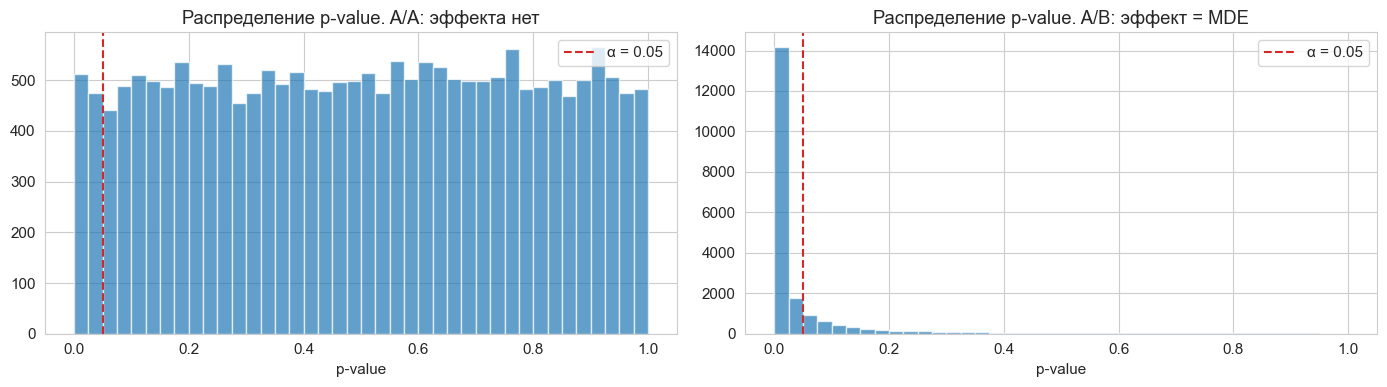

In [10]:
R = 20_000
n_b = round(N * SHARE_B)
n_a = N - n_b


def simulate_pvalues(p_a: float, p_b: float, R: int = R) -> np.ndarray:
    x_a = rng.binomial(n_a, p_a, size=R)
    x_b = rng.binomial(n_b, p_b, size=R)
    return z_test_props(x_a, n_a, x_b, n_b)[1]


p_aa = simulate_pvalues(P_A, P_A)
p_ab = simulate_pvalues(P_A, P_A + MDE)

for name, pv, target in [("A/A: ошибка I рода", p_aa, 0.05), ("A/B: мощность    ", p_ab, 0.80)]:
    k = int((pv < 0.05).sum())
    lo, hi = proportion_confint(k, R, method="wilson")
    print(f"{name}  {k / R:.4f}  95% ДИ [{lo:.4f}, {hi:.4f}]   (ожидаем {target})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, pv, title in [(axes[0], p_aa, "A/A: эффекта нет"), (axes[1], p_ab, "A/B: эффект = MDE")]:
    ax.hist(pv, bins=40, range=(0, 1), color="tab:blue", alpha=0.7)
    ax.axvline(0.05, color="tab:red", ls="--", label="α = 0.05")
    ax.set_title(f"Распределение p-value. {title}")
    ax.set_xlabel("p-value")
    ax.legend()
plt.tight_layout()
plt.show()

**Вопросы.**

1. Почему в A/A-тесте распределение p-value равномерное и что означал бы «горб» слева или справа?
2. Что будет с мощностью, если истинный эффект окажется не +1 п.п., а +0.5 п.п.? Посмотрите на график ниже.

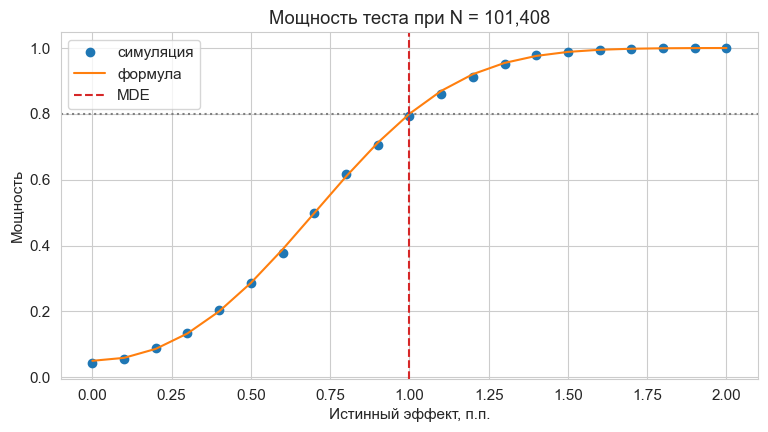

Мощность при эффекте +0.5 п.п.: 0.29


In [11]:
effects = np.linspace(0, 0.02, 21)
powers = [(simulate_pvalues(P_A, P_A + d, R=5_000) < 0.05).mean() for d in effects]
se = np.sqrt(P_A * (1 - P_A) / n_a + (P_A + effects) * (1 - P_A - effects) / n_b)
z_crit = stats.norm.ppf(0.975)
analytic = stats.norm.cdf(effects / se - z_crit) + stats.norm.cdf(-effects / se - z_crit)   # оба хвоста

plt.figure(figsize=(9, 4.5))
plt.plot(effects * 100, powers, "o", label="симуляция")
plt.plot(effects * 100, analytic, "-", label="формула")
plt.axhline(0.8, color="gray", ls=":")
plt.axvline(MDE * 100, color="tab:red", ls="--", label="MDE")
plt.xlabel("Истинный эффект, п.п.")
plt.ylabel("Мощность")
plt.title("Мощность теста при N = %s" % f"{N:,}")
plt.legend()
plt.show()
print(f"Мощность при эффекте +0.5 п.п.: {powers[5]:.2f}")

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. Если $H_0$ верна и статистика действительно имеет то распределение, на которое мы опираемся, то $P(p \le t) = t$ для любого порога $t$ — это и есть равномерное распределение. «Горб» у нуля значит, что критерий **завышает** ошибку I рода (например, наблюдения зависимы, а мы считаем их независимыми — как заказы в 1.П1). «Провал» у нуля значит, что критерий слишком консервативен и теряет мощность.
2. Мощность упадёт примерно до 0.3: тест в двух случаях из трёх не заметит эффект. Более того, если он всё же окажется значимым, оценка эффекта будет **завышенной** — значимыми становятся только те запуски, где шум «подыграл» эффекту (ошибка типа M, лекция 1.06). MDE — это не «эффект, который мы ожидаем», а эффект, который тест надёжно замечает.
</details>

## 3. Анализ результатов

Тест отработал запланированные две недели. Выгрузка из логов — одна строка на пользователя, дошедшего до чекаута:

| Колонка | Смысл |
|---|---|
| `user_id` | идентификатор пользователя |
| `date` | день первого захода на чекаут |
| `group` | A — старый чекаут, B — новый |
| `converted` | оформил ли заказ (0/1) |
| `revenue` | выручка с пользователя, ₽ (0, если заказа нет) |
| `checkout_time_sec` | время на странице чекаута, с |
| `payment_error` | была ли ошибка оплаты (0/1) |

Данные синтетические, их генерирует скрипт [`data/generate_data.py`](data/generate_data.py). Истинные эффекты зашиты в нём — не подглядывайте до конца практики.

In [12]:
LOCAL_PATH = Path("data/checkout_ab.csv")
REPO_PATH = ("1. AB Тесты/Практический блок/02. Тестирование новой страницы чекаута. AB тест на z тесте"
             "/data/checkout_ab.csv")
DATA_URL = "https://raw.githubusercontent.com/Alberelloo/Hypothesis-Testing-Course/main/" + quote(REPO_PATH)

raw = pd.read_csv(LOCAL_PATH if LOCAL_PATH.exists() else DATA_URL)
print(raw.shape)
print(f"Период: {raw['date'].min()} — {raw['date'].max()}")
raw.head()

(105330, 7)
Период: 2026-09-07 — 2026-09-20


,user_id,date,group,converted,revenue,checkout_time_sec,payment_error
0,7480367,2026-09-20,A,1,1214.44,102.3,0
1,9280410,2026-09-12,A,1,2440.60,383.3,0
2,5231080,2026-09-16,B,1,2873.18,101.5,0
3,9684298,2026-09-13,A,1,6206.62,103.7,0
4,1961867,2026-09-12,A,1,1640.35,137.7,0


### Задание 3. Качество данных

Прежде чем считать эффекты, проверим логи. Типичные проблемы:

1. **полные дубли строк** — событие записалось дважды;
2. **пользователи, попавшие в обе группы** — баг сплитования или логирования: мы не знаем, какую версию чекаута они видели.

Реализуйте `clean_data(df)`: удалите полные дубли, затем **целиком** удалите пользователей, которые встречаются в обеих группах. Верните очищенный датафрейм.

In [13]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [14]:
# @title Решение (нажмите, чтобы раскрыть)
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    df = df.drop_duplicates()
    n_groups = df.groupby("user_id")["group"].nunique()
    both = n_groups[n_groups > 1].index
    return df[~df["user_id"].isin(both)].reset_index(drop=True)

In [15]:
# Проверка
df = clean_data(raw)
assert df["user_id"].is_unique, "Остались повторяющиеся user_id"

mismatch_raw = (raw["group"] != raw["user_id"].map(assign_group)).sum()
mismatch_clean = (df["group"] != df["user_id"].map(assign_group)).sum()
print(f"Строк было: {len(raw):,}, стало: {len(df):,}")
print(f"  полных дублей:              {raw.duplicated().sum()}")
print(f"  пользователей в обеих группах: {raw.drop_duplicates().groupby('user_id')['group'].nunique().gt(1).sum()}")
print(f"Строк, где группа не совпадает с хешем: до очистки {mismatch_raw}, после {mismatch_clean}")

Строк было: 105,330, стало: 104,960
  полных дублей:              250
  пользователей в обеих группах: 60
Строк, где группа не совпадает с хешем: до очистки 60, после 0


Сверка с хешем подтверждает диагноз: у пользователей из обеих групп одна из записей не совпадает с тем, что выдаёт `assign_group`, — это ошибка логирования, а не сплитования.

**Вопрос.** Почему мы удаляем таких пользователей целиком, а не оставляем запись, совпадающую с хешем? Чем опасно удаление пользователей по любому признаку, связанному с группой?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Мы не знаем, какую версию чекаута на самом деле видел такой пользователь: может быть, обе. Его метрики «загрязнены», и надёжнее его исключить. Это безопасно, пока таких пользователей мало и проблема **одинаково** затрагивает обе группы. Если же баг бил только по одной группе (например, только новый чекаут на старой версии приложения), то удаление сдвинет состав групп: рандомизация нарушится, и сравнение станет нечестным. Поэтому после любой очистки обязательно проверяем баланс групп — следующий шаг.
</details>

### Sample Ratio Mismatch (SRM)

Мы планировали сплит 80/20. Если фактическое соотношение групп **статистически** отличается от плана, значит, что-то сломалось (сплитование, логирование, фильтрация), и результатам теста доверять нельзя, как бы красиво они ни выглядели. Проверяем критерием согласия $\chi^2$. Порог для SRM обычно берут строгий, например $0.001$: это проверка исправности, и ложная тревога на ней стоит дорого.

In [16]:
counts = df["group"].value_counts().reindex(["A", "B"])
expected = len(df) * np.array([1 - SHARE_B, SHARE_B])
srm_p = stats.chisquare(counts, expected).pvalue
print(f"A: {counts['A']:,}  B: {counts['B']:,}  доля B = {counts['B'] / len(df):.4f}")
print(f"SRM p-value = {srm_p:.3f} -> {'SRM! Ищем причину, эффекты не считаем' if srm_p < 0.001 else 'дисбаланса нет'}")

daily_share = df.groupby("date")["group"].apply(lambda g: (g == "B").mean())
print(f"Доля B по дням: от {daily_share.min():.3f} до {daily_share.max():.3f}")

A: 83,878  B: 21,082  доля B = 0.2009
SRM p-value = 0.487 -> дисбаланса нет
Доля B по дням: от 0.196 до 0.210


### Задание 4. Эффект на конверсию

Решение будем принимать по **доверительному интервалу**, а не только по p-value. Реализуйте `conversion_report(conv_a, conv_b)`: на вход — массивы 0/1 по пользователям, на выход — словарь

* `p_a`, `p_b` — конверсии в группах;
* `abs`, `abs_ci` — абсолютный эффект $\hat p_B - \hat p_A$ и его 95% ДИ;
* `rel`, `rel_ci` — относительный эффект $\hat p_B / \hat p_A - 1$ и его 95% ДИ;
* `p_value` — двусторонний p-value z-теста (используйте `z_test_props`).

Формулы ДИ — из 1.П1 (конверсия — частный случай value-метрики, $\hat\sigma^2_g = \hat p_g(1 - \hat p_g)$):

$$
\widehat{\mathrm{SE}}_{\text{abs}} = \sqrt{\frac{\hat p_A(1-\hat p_A)}{n_A} + \frac{\hat p_B(1-\hat p_B)}{n_B}}, \qquad
\widehat{\mathrm{Var}}_{\text{rel}} = \frac{\hat p_B(1-\hat p_B)}{n_B\,\hat p_A^2} + \frac{\hat p_B^2}{\hat p_A^4}\cdot\frac{\hat p_A(1-\hat p_A)}{n_A}.
$$

Обратите внимание: ДИ строится с **непулированной** дисперсией — он описывает эффект там, где $H_0$ может быть и неверна.

In [17]:
def conversion_report(conv_a, conv_b, alpha: float = 0.05) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [18]:
# @title Решение (нажмите, чтобы раскрыть)
def conversion_report(conv_a, conv_b, alpha: float = 0.05) -> dict:
    conv_a = np.asarray(conv_a, float); conv_b = np.asarray(conv_b, float)
    n_a, n_b = len(conv_a), len(conv_b)
    p_a, p_b = conv_a.mean(), conv_b.mean()
    z = stats.norm.ppf(1 - alpha / 2)

    var_a, var_b = p_a * (1 - p_a) / n_a, p_b * (1 - p_b) / n_b
    abs_eff = p_b - p_a
    se_abs = math.sqrt(var_a + var_b)

    rel_eff = p_b / p_a - 1
    se_rel = math.sqrt(var_b / p_a**2 + p_b**2 / p_a**4 * var_a)

    _, p_value = z_test_props(conv_a.sum(), n_a, conv_b.sum(), n_b)
    return {"p_a": p_a, "p_b": p_b,
            "abs": abs_eff, "abs_ci": (abs_eff - z * se_abs, abs_eff + z * se_abs),
            "rel": rel_eff, "rel_ci": (rel_eff - z * se_rel, rel_eff + z * se_rel),
            "p_value": float(p_value)}

In [19]:
# Проверка
A, B = df[df["group"] == "A"], df[df["group"] == "B"]
rep = conversion_report(A["converted"], B["converted"])

lo_sm, hi_sm = confint_proportions_2indep(B["converted"].sum(), len(B), A["converted"].sum(), len(A),
                                          method="wald", compare="diff")
assert np.allclose(rep["abs_ci"], (lo_sm, hi_sm)), "ДИ абсолютного эффекта не совпадает со statsmodels"

print(f"Конверсия: A = {rep['p_a']:.2%}, B = {rep['p_b']:.2%}")
print(f"Абсолютный эффект: {rep['abs'] * 100:+.2f} п.п.  95% ДИ [{rep['abs_ci'][0] * 100:+.2f}, {rep['abs_ci'][1] * 100:+.2f}]")
print(f"Относительный:     {rep['rel']:+.2%}      95% ДИ [{rep['rel_ci'][0]:+.2%}, {rep['rel_ci'][1]:+.2%}]")
print(f"p-value = {rep['p_value']:.5f}")

extra = np.array([rep["abs"], *rep["abs_ci"]]) * DAILY_USERS
print(f"\nПри раскатке на всех: {extra[0]:+.0f} заказов в день, 95% ДИ [{extra[1]:+.0f}, {extra[2]:+.0f}]")

Конверсия: A = 69.86%, B = 71.25%
Абсолютный эффект: +1.39 п.п.  95% ДИ [+0.70, +2.07]
Относительный:     +1.99%      95% ДИ [+1.00%, +2.97%]
p-value = 0.00008

При раскатке на всех: +104 заказов в день, 95% ДИ [+53, +156]


**Вопрос.** Эффект значим. Можно ли сказать владельцу продукта, что цель «+1 п.п.» достигнута?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет, по крайней мере не так уверенно. Значимость говорит только, что эффект **не нулевой**. Точечная оценка выше 1 п.п., но нижняя граница ДИ — около +0.7 п.п.: данные согласуются и с эффектом меньше цели. Честная формулировка: «новый чекаут поднимает конверсию; лучшая оценка — около +1.4 п.п., с 95% уверенностью — от +0.7 до +2.1 п.п.». ДИ, переведённый в заказы в день, понятнее бизнесу, чем p-value.

Сравнение ДИ с MDE — полезная привычка: если бы весь ДИ лежал ниже MDE, эффект был бы статистически значимым, но практически незначимым.
</details>

## 4. Несколько метрик и итоговое решение

На одну конверсию в реальном тесте не смотрят. До запуска мы договорились о **ролях метрик** и о **правиле решения** — это делается заранее, чтобы потом не подгонять выводы под результат.

| Метрика | Колонка | Роль | Что хотим | Альтернатива |
|---|---|---|---|---|
| Конверсия в заказ | `converted` | **основная** | рост | двусторонняя |
| Выручка на пользователя (ARPU) | `revenue` | вторичная | рост | двусторонняя |
| Время на чекауте | `checkout_time_sec` | вторичная | снижение | двусторонняя |
| Доля пользователей с ошибкой оплаты | `payment_error` | **контрольная** (guardrail) | не вырасти | односторонняя: B хуже A |

**Правило решения:**

1. Новый чекаут **раскатываем**, если основная метрика значимо выросла **и** контрольная значимо не ухудшилась.
2. Вторичные метрики помогают понять механизм эффекта. Их несколько, поэтому применяем к ним **поправку Холма**: иначе с ростом числа метрик растёт шанс случайно «найти» эффект хоть где-то (лекция 1.03).
3. Контрольную метрику проверяем **односторонне и без поправки**: здесь страшнее пропустить вред (ошибка II рода), чем лишний раз поднять тревогу (ошибка I рода). Поправка ослабила бы её чувствительность к вреду.

Основная метрика одна, поэтому её α не делим.

### Задание 5. Тест для средних

Все четыре метрики — средние по пользователям (конверсия и ошибка оплаты — средние 0/1). Реализуйте `mean_test(x_a, x_b, alternative)` — z-тест для разности средних с непулированной дисперсией (при наших размерах выборок он совпадает с t-тестом Уэлча):

* `effect` — $\bar x_B - \bar x_A$, `ci` — его двусторонний 95% ДИ;
* `uplift` — $\bar x_B / \bar x_A - 1$;
* `p_value`: при `alternative="two-sided"` — двусторонний, при `alternative="larger"` — односторонний для $H_1: \mu_B > \mu_A$.

In [20]:
def mean_test(x_a, x_b, alternative: str = "two-sided", alpha: float = 0.05) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [21]:
# @title Решение (нажмите, чтобы раскрыть)
def mean_test(x_a, x_b, alternative: str = "two-sided", alpha: float = 0.05) -> dict:
    x_a = np.asarray(x_a, float); x_b = np.asarray(x_b, float)
    effect = x_b.mean() - x_a.mean()
    se = math.sqrt(x_a.var(ddof=1) / len(x_a) + x_b.var(ddof=1) / len(x_b))
    z = effect / se
    p_value = 2 * stats.norm.sf(abs(z)) if alternative == "two-sided" else stats.norm.sf(z)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    return {"effect": effect, "ci": (effect - z_crit * se, effect + z_crit * se),
            "uplift": x_b.mean() / x_a.mean() - 1, "p_value": p_value}

In [22]:
# Проверка
res = mean_test(A["revenue"], B["revenue"])
p_welch = stats.ttest_ind(B["revenue"], A["revenue"], equal_var=False).pvalue
assert abs(res["p_value"] - p_welch) < 1e-3, "p-value сильно расходится с тестом Уэлча"
res_one = mean_test(A["payment_error"], B["payment_error"], alternative="larger")
p_welch_one = stats.ttest_ind(B["payment_error"], A["payment_error"], equal_var=False, alternative="greater").pvalue
assert abs(res_one["p_value"] - p_welch_one) < 1e-3, "Односторонний p-value расходится с тестом Уэлча"
print("Совпадает с тестом Уэлча")

Совпадает с тестом Уэлча


Соберём результаты по всем метрикам и применим поправки по правилу решения.

In [23]:
METRICS = [  # (колонка, название, роль, альтернатива)
    ("converted",         "Конверсия в заказ",   "основная",    "two-sided"),
    ("revenue",           "ARPU, ₽",             "вторичная",   "two-sided"),
    ("checkout_time_sec", "Время на чекауте, с", "вторичная",   "two-sided"),
    ("payment_error",     "Ошибки оплаты",       "контрольная", "larger"),
]
rows = []
for col, name, role, alt in METRICS:
    r = mean_test(A[col], B[col], alternative=alt)
    rows.append({"метрика": name, "роль": role, "A": A[col].mean(), "B": B[col].mean(),
                 "эффект": r["effect"], "ДИ_low": r["ci"][0], "ДИ_high": r["ci"][1],
                 "uplift": r["uplift"], "p_value": r["p_value"]})
results = pd.DataFrame(rows).set_index("метрика")

# Поправки — только внутри семейства вторичных метрик
secondary = results["роль"] == "вторичная"
results["p_adj"] = results["p_value"]
results.loc[secondary, "p_adj"] = multipletests(results.loc[secondary, "p_value"], method="holm")[1]
results["значимо"] = results["p_adj"] < 0.05
results.round(5)

,роль,A,B,эффект,ДИ_low,ДИ_high,uplift,p_value,p_adj,значимо
метрика,,,,,,,,,,
Конверсия в заказ,основная,0.69857,0.71246,0.01388,0.00703,0.02074,0.01987,0.00007,0.00007,True
"ARPU, ₽",вторичная,2363.94014,2399.12514,35.18500,-11.59073,81.96074,0.01488,0.14040,0.14040,False
"Время на чекауте, с",вторичная,114.04397,111.55506,-2.48891,-3.61643,-1.36139,-0.02182,0.00002,0.00003,True
Ошибки оплаты,контрольная,0.02014,0.02234,0.00220,-0.00000,0.00441,0.10950,0.02526,0.02526,True


**Анти-пример.** Что было бы, если бы мы не договорились о ролях заранее, а просто прогнали все четыре метрики двусторонними тестами и «для надёжности» применили поправку ко всем сразу?

In [24]:
p_two_sided = [mean_test(A[col], B[col])["p_value"] for col, *_ in METRICS]
naive = pd.DataFrame({"p_value (двусторонний)": p_two_sided,
                      "Холм по всем 4": multipletests(p_two_sided, method="holm")[1],
                      "BH по всем 4": multipletests(p_two_sided, method="fdr_bh")[1]},
                     index=results.index)
naive.round(4)

,p_value (двусторонний),Холм по всем 4,BH по всем 4
метрика,,,
Конверсия в заказ,0.0001,0.0002,0.0001
"ARPU, ₽",0.1404,0.1404,0.1404
"Время на чекауте, с",0.0000,0.0001,0.0001
Ошибки оплаты,0.0505,0.1010,0.0674


### Задание 6. Решение

Сформулируйте итоговое решение по правилу выше и короткий вывод для владельца продукта (3–5 предложений): что произошло с каждой метрикой и что делаем дальше. Сравните с анти-примером: какой вывод сделала бы команда, «поправив» всё подряд?

*Ваш ответ:*

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Конверсия** значимо выросла: около +1.4 п.п., 95% ДИ примерно от +0.7 до +2.1 п.п.
* **ARPU** вырос на ≈1.5%, но незначимо (ДИ от −12 до +82 ₽): выручка — шумная метрика с тяжёлым хвостом, и 21 тыс. пользователей в B мало, чтобы надёжно увидеть эффект такого размера. Направление согласуется с конверсией: заказов стало больше, а средний чек, по-видимому, не изменился.
* **Время на чекауте** значимо сократилось примерно на 2% и после поправки Холма — новая страница действительно проще.
* **Ошибки оплаты** выросли примерно на 0.2 п.п. (≈ +11% относительно), односторонний p-value около 0.025 — **контрольная метрика сработала**.

**Решение:** по заранее зафиксированному правилу новый чекаут **как есть не раскатываем**. Конверсия растёт, но вместе с ней растут ошибки оплаты — это сигнал о баге в новой версии (например, в отдельном способе оплаты или на одной из платформ). Задача команде: найти и исправить причину, после чего провести короткий подтверждающий тест. Менять правило задним числом («ну, конверсия же выросла») нельзя — это та же подгонка под результат, от которой нас защищает пре-регистрация.

**Анти-пример:** двусторонний тест для ошибок оплаты даёт p ≈ 0.05 — ровно на границе, а поправка Холма по всем четырём метрикам поднимает его до ≈ 0.10. Команда увидела бы «значимый рост конверсии и никакого вреда» и раскатила бы версию с багом оплаты на всех пользователей. Поправки защищают от ложных **открытий**; для контрольных метрик, где мы ищем **вред**, они работают против нас.
</details>

Итоговая таблица для отчёта: эффект с ДИ важнее голого p-value.

In [25]:
def fmt(name, v):
    return f"{v:.2%}" if name in ("Конверсия в заказ", "Ошибки оплаты") else f"{v:,.1f}"


report = pd.DataFrame({
    "роль": results["роль"],
    "A": [fmt(n, v) for n, v in results["A"].items()],
    "B": [fmt(n, v) for n, v in results["B"].items()],
    "эффект (95% ДИ)": [
        f"{r.эффект * 100:+.2f} п.п. [{r.ДИ_low * 100:+.2f}; {r.ДИ_high * 100:+.2f}]"
        if n in ("Конверсия в заказ", "Ошибки оплаты")
        else f"{r.эффект:+,.1f} [{r.ДИ_low:+,.1f}; {r.ДИ_high:+,.1f}]"
        for n, r in results.iterrows()],
    "uplift": results["uplift"].map("{:+.1%}".format),
    "p-value": results["p_adj"].map("{:.4f}".format),
    "вывод": ["✅ рост" if s and e > 0 else "✅ снижение" if s and e < 0 else "— незначимо"
              for s, e in zip(results["значимо"], results["эффект"])],
}, index=results.index)
report.loc["Ошибки оплаты", "вывод"] = "❌ ухудшение" if results.loc["Ошибки оплаты", "значимо"] else "✅ не ухудшилась"
report

,роль,A,B,эффект (95% ДИ),uplift,p-value,вывод
метрика,,,,,,,
Конверсия в заказ,основная,69.86%,71.25%,+1.39 п.п. [+0.70; +2.07],+2.0%,0.0001,✅ рост
"ARPU, ₽",вторичная,"2,363.9","2,399.1",+35.2 [-11.6; +82.0],+1.5%,0.1404,— незначимо
"Время на чекауте, с",вторичная,114.0,111.6,-2.5 [-3.6; -1.4],-2.2%,0.0000,✅ снижение
Ошибки оплаты,контрольная,2.01%,2.23%,+0.22 п.п. [-0.00; +0.44],+11.0%,0.0253,❌ ухудшение


Обратите внимание на ошибки оплаты: двусторонний 95% ДИ касается нуля, а тест значим. Противоречия нет. Двусторонний 95% ДИ соответствует двустороннему тесту на уровне 0.05, а односторонний тест на уровне 0.05 — нижней границе **90%** ДИ, и она выше нуля. Для контрольной метрики в отчёте честнее показывать именно одностороннюю границу.

## 5. От чего зависит размер выборки

### Задание 7. Гипотезы

**До** запуска ячейки с графиками запишите, как, по-вашему, общий размер выборки $N$ зависит от каждого параметра при остальных фиксированных (рост / падение, линейно или быстрее, есть ли минимум или максимум):

1. доля трафика в группе B;
2. уровень значимости $\alpha$;
3. мощность $1 - \beta$;
4. абсолютный MDE $\delta$;
5. базовая конверсия $p_A$ при фиксированном **абсолютном** MDE (+1 п.п.);
6. базовая конверсия $p_A$ при фиксированном **относительном** MDE.

*Ваш ответ:*

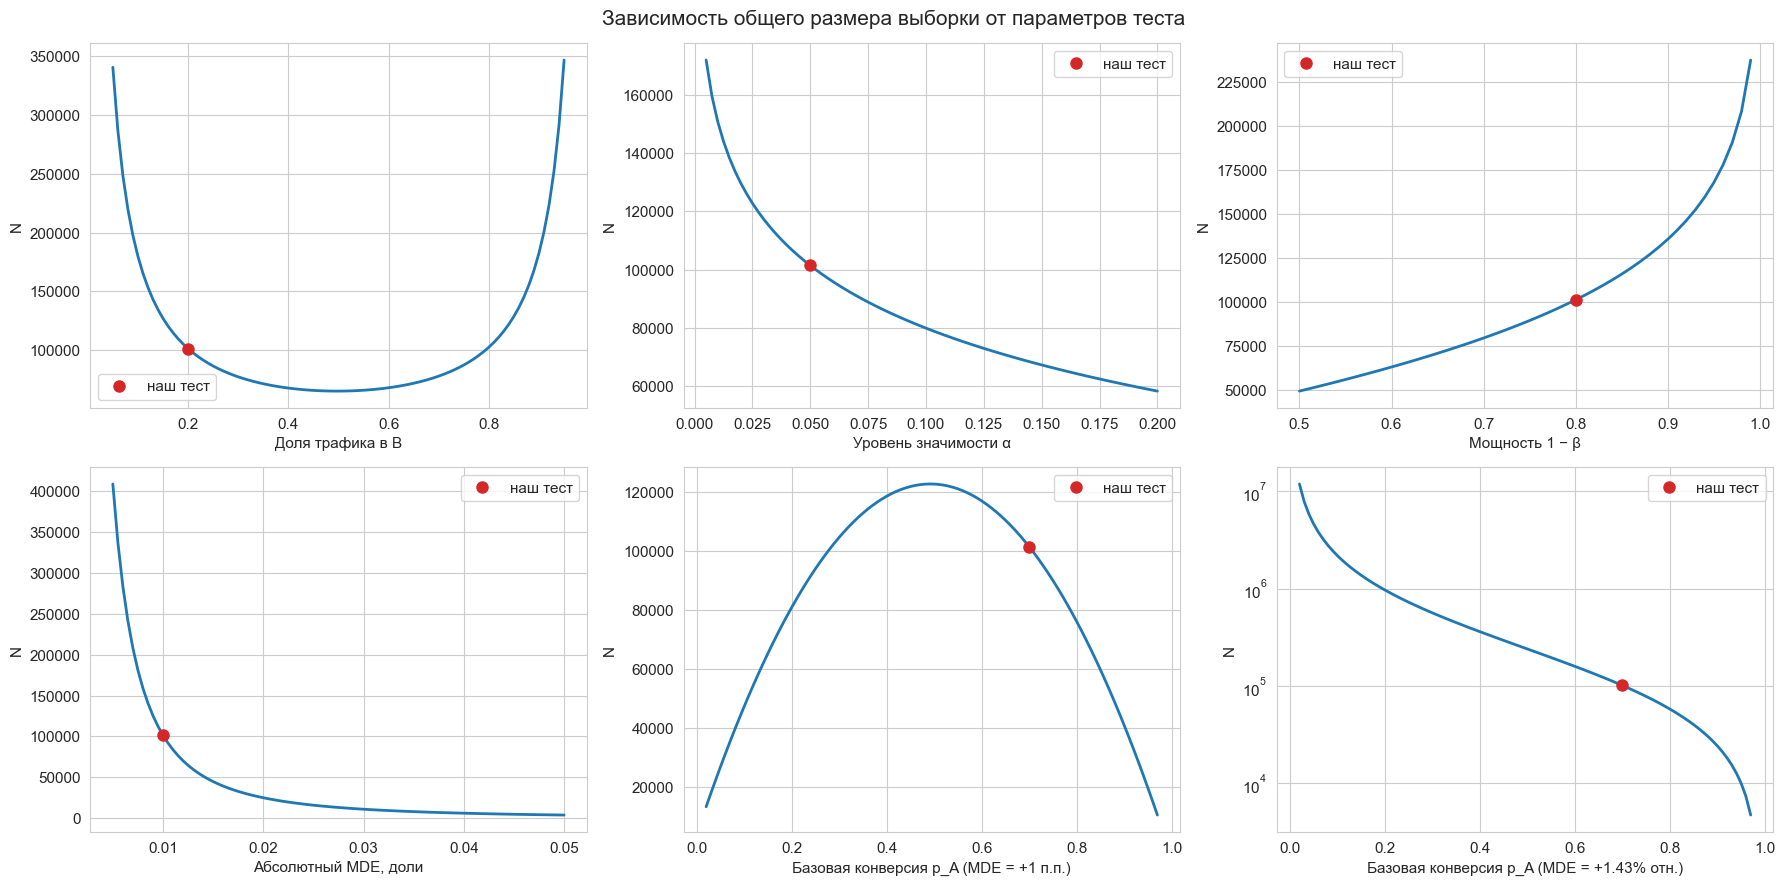

In [26]:
BASE = dict(p_a=P_A, mde=MDE, share_b=SHARE_B, alpha=0.05, power=0.8)
REL_MDE = MDE / P_A   # относительный MDE, совпадающий с +1 п.п. при p_A = 70%

panels = [  # (параметр, сетка значений, подпись оси X)
    ("share_b", np.linspace(0.05, 0.95, 91),  "Доля трафика в B"),
    ("alpha",   np.linspace(0.005, 0.2, 79),  "Уровень значимости α"),
    ("power",   np.linspace(0.5, 0.99, 50),   "Мощность 1 − β"),
    ("mde",     np.linspace(0.005, 0.05, 91), "Абсолютный MDE, доли"),
    ("p_a",     np.linspace(0.02, 0.97, 96),  "Базовая конверсия p_A (MDE = +1 п.п.)"),
    ("p_a_rel", np.linspace(0.02, 0.97, 96),  f"Базовая конверсия p_A (MDE = +{REL_MDE:.2%} отн.)"),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (param, grid, label) in zip(axes.ravel(), panels):
    if param == "p_a_rel":
        ns = [sample_size_total(**{**BASE, "p_a": p, "mde": p * REL_MDE}) for p in grid]
        ax.set_yscale("log")
        current = P_A
    else:
        ns = [sample_size_total(**{**BASE, param: v}) for v in grid]
        current = BASE[param]
    ax.plot(grid, ns, lw=2)
    ax.plot(current, N, "o", color="tab:red", ms=8, label="наш тест")
    ax.set_xlabel(label)
    ax.set_ylabel("N")
    ax.legend()
plt.suptitle("Зависимость общего размера выборки от параметров теста", fontsize=15)
plt.tight_layout()
plt.show()

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. **Доля B** — U-образная кривая с минимумом около 50/50: $N \propto \frac{\sigma_A^2}{w_A} + \frac{\sigma_B^2}{w_B}$. При 80/20 платим в ≈1.56 раза больше, при 95/5 — уже в ≈5 раз. Небольшие перекосы почти бесплатны, сильные — очень дороги.
2. **α** — $N \propto (z_{1-\alpha/2} + z_{1-\beta})^2$: чем строже α, тем больше выборка, и рост ускоряется при малых α. Переход от 0.05 к 0.01 стоит ≈ +49%.
3. **Мощность** — тоже через квадрат суммы квантилей, рост резко ускоряется у единицы: 0.8 → 0.9 стоит ≈ +34%, 0.8 → 0.99 — в ≈2.3 раза больше.
4. **MDE** — $N \propto 1/\delta^2$: чтобы замечать вдвое меньший эффект, нужно вчетверо больше пользователей. Это самый сильный рычаг.
5. **Базовая конверсия при абсолютном MDE** — перевёрнутая U с максимумом около 0.5: дисперсия бернуллиевской величины $p(1-p)$ максимальна при $p = 0.5$.
6. **Базовая конверсия при относительном MDE** — $N \propto \frac{1-p}{p}$, растёт на порядки при малых конверсиях (шкала логарифмическая). Поэтому тесты на редкие события (покупка подписки, конверсия из показа рекламы) требуют огромных выборок, а тесты на «верхние» шаги воронки, как наш чекаут, сравнительно дешёвы.
</details>

## Итоги

**Пайплайн A/B теста, который мы прошли:**

1. **До запуска:** гипотеза и сторона альтернативы; метрики и их роли; MDE (абсолютный или относительный — уточняем у заказчика); α и мощность; размер выборки и длительность в целых неделях; правило решения.
2. **Проверка критерия на симуляциях:** A/A — ошибка I рода ≈ α и равномерные p-value; A/B — мощность на уровне MDE.
3. **После теста, до эффектов:** качество данных (дубли, пользователи в обеих группах, сверка с хешем) и SRM. Если SRM есть — сначала ищем причину.
4. **Эффект:** оценка с ДИ — абсолютным и относительным, ДИ сравниваем с MDE, переводим в бизнес-единицы.
5. **Несколько метрик:** поправки на множественность — для семейства метрик, где мы ищем улучшения; контрольные метрики проверяем односторонне и без поправок.

### Дополнительные задания

1. **Подглядывание.** Разбейте данные по дням и посчитайте p-value конверсии накопленным итогом после каждого дня. Затем на симуляциях A/A-тестов оцените, какой была бы ошибка I рода, если бы команда останавливала тест в первый же день, когда $p < 0.05$.
2. **Обратная задача.** Какой минимальный абсолютный эффект тест мог бы надёжно (с мощностью 0.8) заметить, если бы шёл одну неделю при сплите 80/20? А при 50/50?
3. **Non-inferiority для ошибок оплаты.** Вместо проверки «B хуже A» проверьте гипотезу не меньшей эффективности: $H_0: p_B - p_A \ge 0.3$ п.п. против $H_1: p_B - p_A < 0.3$ п.п. Можно ли утверждать, что ошибки оплаты выросли не больше чем на 0.3 п.п.? Чем такой подход к контрольным метрикам лучше нашего (см. статью Spotify в источниках)?

### Источники

1. [A/B testing and the z-test (Bytepawn)](https://bytepawn.com/ab-testing-and-the-ztest.html)
2. [Power Analysis (Chabé-Ferret, Statistical Tools for Causal Inference)](https://chabefer.github.io/STCI/Power.html#basics-of-traditional-power-analysis-using-test-statistics)
3. [Проверка валидности критерия (X5 Tech)](https://habr.com/ru/companies/X5Tech/articles/706388/)
4. [Schultzberg, Ankargren, Frånberg — Risk-aware product decisions in A/B tests with multiple metrics (Spotify)](https://arxiv.org/abs/2402.11609)
5. [Superiority vs Non-inferiority тесты (Analytics-Toolkit)](https://blog.analytics-toolkit.com/2017/case-non-inferiority-designs-ab-testing/)
6. Kohavi, Tang, Xu — *Trustworthy Online Controlled Experiments: A Practical Guide to A/B Testing* (Cambridge University Press, 2020), глава 21 о Sample Ratio Mismatch.